# Exploring the clue vocabulary (Stage 0 prototype)

This notebook plays through **Stage 0** of the pipeline (see `../CLAUDE.md`, "Data §2" and
"Pipeline → Stage 0"): building `clue_vocab.txt` from the `wordfreq` top-50k English word
list, filtered down to the `N` most useful clue candidates.

This is exploration, not the final implementation — once the approach here looks right,
it gets formalized into `codemaster.pipeline.vocab` as a proper, tested, `--limit`-able
pipeline stage. Nothing here is committed as pipeline code yet.

**Recap of the spec:**
- Source: `wordfreq.top_n_list("en", 50_000)`.
- Filters: alphabetic only, length ≥ 3, drop stopwords, collapse inflections to lemmas
  (keep the most frequent surface form), drop a small profanity blocklist. **No POS
  filter** — verbs and adjectives are legal clues.
- Do **not** remove card words globally (board-specific filtering happens at game time).
- Keep the top `N` after filtering (default 10,000).
- Store log-frequency alongside each word for the codemaster's familiarity penalty.


In [1]:
import re
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import wordfreq
from lemminflect import getAllLemmas
from spacy.lang.en.stop_words import STOP_WORDS

N_DEFAULT = 10_000
RAW_SIZE = 50_000


## 1. The raw list

`wordfreq.top_n_list("en", 50_000)` is already frequency-sorted (most common first). We'll
track the word count after each filter so we can see where the list shrinks.


In [2]:
raw_words = wordfreq.top_n_list("en", RAW_SIZE)
print(f"{len(raw_words):,} raw words")
print("most frequent:", raw_words[:15])
print("least frequent:", raw_words[-15:])


50,000 raw words
most frequent: ['the', 'to', 'and', 'of', 'a', 'in', 'i', 'is', 'for', 'that', 'you', 'it', 'on', 'with', 'this']
least frequent: ['holtby', 'holton', 'hoodoo', 'horsham', 'hrh', 'hubbell', 'hummels', 'hygienist', 'hypertext', 'idolized', 'ilan', 'illegible', 'immunities', 'immunological', 'impertinent']


## 2. Log-frequency

`wordfreq.zipf_frequency` is already a log10-based scale (roughly 0–8: "occurrences per
billion words", logged and offset) — this is what we'll store as each word's log-frequency
for the familiarity penalty, rather than inventing our own log transform.


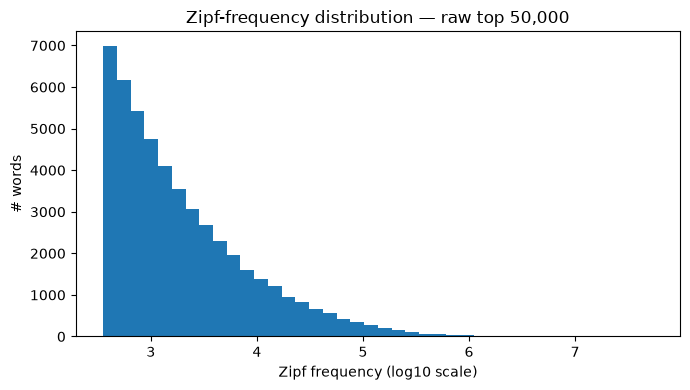

In [3]:
zipf = {w: wordfreq.zipf_frequency(w, "en") for w in raw_words}

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(list(zipf.values()), bins=40)
ax.set_xlabel("Zipf frequency (log10 scale)")
ax.set_ylabel("# words")
ax.set_title(f"Zipf-frequency distribution — raw top {RAW_SIZE:,}")
plt.tight_layout()
plt.show()


## 3. Filter: alphabetic only, length ≥ 3

`wordfreq`'s list includes things like contractions, single letters, and tokens with
punctuation or digits — none of which make legal Codenames clues.


In [4]:
stage_counts = {"raw": len(raw_words)}

alpha_words = [w for w in raw_words if w.isalpha() and len(w) >= 3]
stage_counts["alphabetic, len>=3"] = len(alpha_words)

dropped = [w for w in raw_words if w not in set(alpha_words)]
print(f"{len(alpha_words):,} words remain ({len(dropped):,} dropped)")
print("sample dropped:", dropped[:20])


47,443 words remain (2,557 dropped)
sample dropped: ['to', 'of', 'a', 'in', 'i', 'is', 'it', 'on', 'be', 'as', 'at', 'he', 'by', 'my', 'or', 'we', 'an', 'so', 'me', 'if']


## 4. Filter: stopwords

Using spaCy's English stopword list (`spacy.lang.en.stop_words.STOP_WORDS`) rather than
hand-rolling one — it's already a dependency and reasonably comprehensive.


In [5]:
non_stop_words = [w for w in alpha_words if w.lower() not in STOP_WORDS]
stage_counts["non-stopword"] = len(non_stop_words)

dropped_stop = [w for w in alpha_words if w not in set(non_stop_words)]
print(f"{len(non_stop_words):,} words remain ({len(dropped_stop):,} dropped)")
print("sample dropped:", dropped_stop[:20])


47,170 words remain (273 dropped)
sample dropped: ['the', 'and', 'for', 'that', 'you', 'with', 'this', 'was', 'are', 'have', 'not', 'but', 'from', 'your', 'all', 'his', 'they', 'one', 'can', 'will']


## 5. Filter: profanity blocklist

**Placeholder list** — small and obviously non-exhaustive, just to prove the filter stage
works end to end. Swap in a real blocklist (or a package like `better-profanity`) before
this becomes the real pipeline stage.


In [6]:
PROFANITY_BLOCKLIST_PLACEHOLDER = {
    "damn", "hell", "ass", "bastard", "bitch", "crap", "slut", "whore",
}

clean_words = [w for w in non_stop_words if w.lower() not in PROFANITY_BLOCKLIST_PLACEHOLDER]
stage_counts["non-profanity"] = len(clean_words)

dropped_profanity = [w for w in non_stop_words if w not in set(clean_words)]
print(f"{len(clean_words):,} words remain ({len(dropped_profanity):,} dropped)")
print("dropped:", dropped_profanity)


47,162 words remain (8 dropped)
dropped: ['hell', 'damn', 'ass', 'bitch', 'crap', 'bastard', 'whore', 'slut']


## 6. Filter: collapse inflections to lemmas

For each word, ask `lemminflect.getAllLemmas` for its lemma under every POS it recognizes
(no sentence context, since this is a vocabulary-level pass, not per-occurrence). We pick
one lemma per word with a priority order (VERB > NOUN > ADJ > ADV), group words that share
a lemma, and within each group keep **only the single highest-frequency surface form**.

Caveat worth flagging: without real POS context, this is a heuristic. `"running"` leans
VERB-first here, so it collapses into the `run` group with `"runs"`/`"ran"` — reasonable
for a game clue, but it's a judgment call, not a certainty. Spot-check the groups below.


In [7]:
POS_PRIORITY = ("VERB", "NOUN", "ADJ", "ADV")

def lemma_key(word: str) -> str:
    lemmas_by_pos = getAllLemmas(word.lower())
    for pos in POS_PRIORITY:
        if pos in lemmas_by_pos:
            return lemmas_by_pos[pos][0]
    return word.lower()

groups = defaultdict(list)
for w in clean_words:
    groups[lemma_key(w)].append(w)

# Keep the single most frequent surface form per lemma group.
collapsed_words = [max(members, key=lambda w: zipf[w]) for members in groups.values()]
stage_counts["lemma-collapsed"] = len(collapsed_words)

print(f"{len(collapsed_words):,} words remain after collapsing "
      f"{len(clean_words):,} surface forms into {len(groups):,} lemma groups")


34,714 words remain after collapsing 47,162 surface forms into 34,714 lemma groups


In [8]:
# Spot-check a few multi-member groups to sanity-check the collapsing logic.
multi_member_groups = {k: v for k, v in groups.items() if len(v) > 1}
sample_keys = ["run", "play", "good", "cat"]
for key in sample_keys:
    if key in multi_member_groups:
        members = multi_member_groups[key]
        kept = max(members, key=lambda w: zipf[w])
        print(f"{key!r}: {members} -> kept {kept!r}")


'run': ['run', 'running', 'ran', 'runs'] -> kept 'run'
'play': ['play', 'playing', 'played', 'plays'] -> kept 'play'
'good': ['good', 'goods'] -> kept 'good'
'cat': ['cat', 'cats'] -> kept 'cat'


## 7. Keep the top N

Everything above only *removes* words; now we re-sort what's left by frequency and keep
the top `N` (default 10,000 — see `configs/base.yaml`).


In [9]:
def build_clue_vocab(n: int = N_DEFAULT):
    ranked = sorted(collapsed_words, key=lambda w: zipf[w], reverse=True)
    top_n = ranked[:n]
    return [(w, zipf[w]) for w in top_n]

clue_vocab = build_clue_vocab(N_DEFAULT)
stage_counts[f"top N={N_DEFAULT:,}"] = len(clue_vocab)

print(f"final clue vocabulary: {len(clue_vocab):,} words")
print("highest frequency:", clue_vocab[:10])
print("lowest frequency (the tail of the top N):", clue_vocab[-10:])


final clue vocabulary: 10,000 words
highest frequency: [('like', 6.41), ('time', 6.29), ('new', 6.25), ('people', 6.25), ('good', 6.12), ('know', 6.1), ('think', 6.08), ('want', 6.04), ('said', 6.01), ('way', 6.01)]
lowest frequency (the tail of the top N): [('sharia', 3.49), ('showdown', 3.49), ('shuffle', 3.49), ('simulated', 3.49), ('skyline', 3.49), ('slab', 3.49), ('suarez', 3.49), ('supplemental', 3.49), ('swimmer', 3.49), ('tao', 3.49)]


## 8. Visualize the filtering funnel

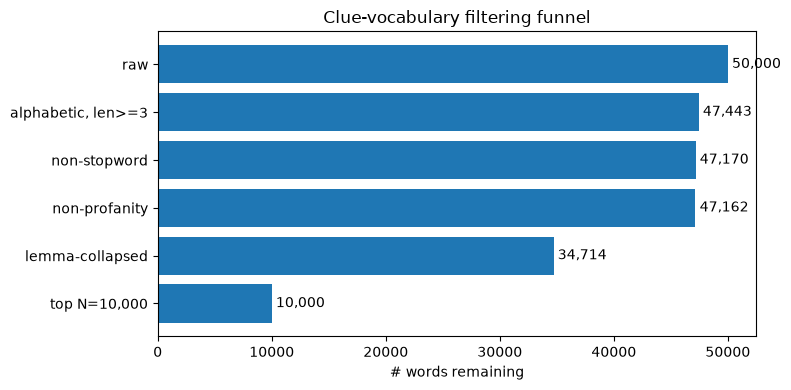

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = list(stage_counts.keys())
values = list(stage_counts.values())
bars = ax.barh(labels, values)
ax.bar_label(bars, labels=[f"{v:,}" for v in values], padding=3)
ax.invert_yaxis()
ax.set_xlabel("# words remaining")
ax.set_title("Clue-vocabulary filtering funnel")
plt.tight_layout()
plt.show()


## 9. Final vocabulary: frequency and length distributions

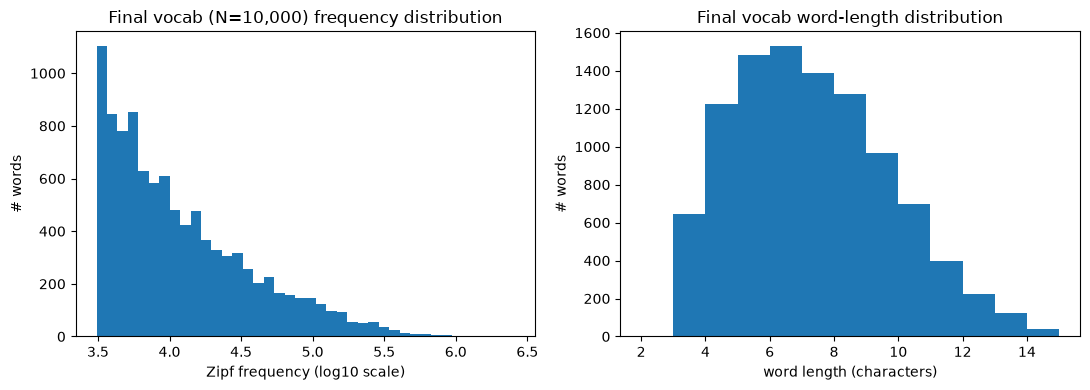

In [11]:
final_zipfs = [z for _, z in clue_vocab]
final_lengths = [len(w) for w, _ in clue_vocab]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(final_zipfs, bins=40)
axes[0].set_xlabel("Zipf frequency (log10 scale)")
axes[0].set_ylabel("# words")
axes[0].set_title(f"Final vocab (N={len(clue_vocab):,}) frequency distribution")

axes[1].hist(final_lengths, bins=range(2, 16))
axes[1].set_xlabel("word length (characters)")
axes[1].set_ylabel("# words")
axes[1].set_title("Final vocab word-length distribution")

plt.tight_layout()
plt.show()


## 10. How sensitive is this to N?

The roadmap calls for sweeping N ∈ {5k, 10k, 20k, 40k} against self-play win rate later —
for now, just see how the frequency floor moves.


In [12]:
for n in (5_000, 10_000, 20_000, 40_000):
    vocab_n = build_clue_vocab(n)
    floor_word, floor_zipf = vocab_n[-1]
    print(f"N={n:>6,}: frequency floor = {floor_zipf:.2f} ({floor_word!r})")


N= 5,000: frequency floor = 3.95 ('goin')
N=10,000: frequency floor = 3.49 ('tao')
N=20,000: frequency floor = 2.98 ('ointment')
N=40,000: frequency floor = 2.55 ('impertinent')


## 11. (Optional) write a preview file

Writes a preview CSV to `data/` for manual spot-checking — gitignored (see root
`.gitignore`), so this is safe to run freely. The real `clue_vocab.txt` gets written by the
formal pipeline stage, not this notebook.


In [13]:
import csv
from pathlib import Path

preview_path = Path("../data/clue_vocab_preview.csv")  # notebook cwd is notebooks/
preview_path.parent.mkdir(exist_ok=True)
with preview_path.open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["word", "zipf_frequency"])
    writer.writerows(clue_vocab)

print(f"wrote {len(clue_vocab):,} rows to {preview_path}")


wrote 10,000 rows to ../data/clue_vocab_preview.csv


## Open questions / TODO before this becomes a real pipeline stage

- The profanity blocklist above is a placeholder — needs a real source before Stage 0 ships.
- Lemma-collapsing is POS-heuristic, not context-aware (see §6 caveat) — worth deciding
  whether that's good enough or needs per-occurrence lemmatization instead.
- `cards.txt` isn't loaded here yet (Stage 0 also builds the surface-form → lemma map for
  card words); add that once `data/cards.txt` exists.
- No profiling yet on how long this takes at the full 50k scale with the real blocklist.
